# DrugCell: three final GO graphs

Compare the exact hierarchies used by three DrugCell models:

1. **A · Official released GO** — 2,086 modules and 3,008 connected genes.
2. **B · Complete GO → pruned** — the project reconstruction using GO 2026-07-26 and matching human annotations; 1,641 modules and 2,984 connected genes.
3. **C · Complete GO → database augmentation → pruned** — the frozen database-only augmentation from run 006; 2,150 modules and 2,997 connected genes.

All panels show **final graphs after pruning**. The shared measured universe has 3,008 genes; the connected input columns differ between models. A/B differences include GO/annotation versions, identifier mapping and the reconstructed pruning implementation. B/C share the same complete-GO source and pruning program.

Identical identifiers keep identical positions. The overview aligns nodes by the **union DAG**, which has nine display bands; each model separately has **six hierarchy levels**. Colors identify GO retained in B/C, GO retained in one rebuilt graph, GO unique to A, and external modules.

The notebook contains saved figures and tables. To rerun, select **Python (GO enrichment)** from the project's `.venv`.


In [1]:
from pathlib import Path
import hashlib
import html
import json
import sys
import pandas as pd
from IPython.display import display, Image, HTML

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "scripts/visualize_drugcell_full_go.py").is_file())
ARTIFACTS = ROOT / "outputs/analysis/drugcell_three_graphs_006_001"
GENE = "TP53"
TERM = "GO:0006281"  # DNA repair; change this identifier to explore another module.

manifest = json.loads((ARTIFACTS / "manifest.json").read_text())
for record in manifest["sources"].values():
    assert hashlib.sha256(Path(record["path"]).read_bytes()).hexdigest() == record["sha256"]
assert hashlib.sha256((ARTIFACTS / "graph_data.json").read_bytes()).hexdigest() == manifest["artifacts"]["graph_data.json"]
data = json.loads((ARTIFACTS / "graph_data.json").read_text())
stages = {stage["id"]: stage for stage in data["stages"]}
node_maps = {key: {n["id"]: n for n in stage["nodes"]} for key, stage in stages.items()}
all_nodes = {n["id"]: n for stage in data["stages"] for n in stage["nodes"]}
assert [s["stats"]["terms"] for s in data["stages"]] == [2086, 1641, 2150]
print("Verified frozen inputs and plotted data.")
print("Experiment:", data["experiment"])
print("Shared measured gene universe:", len(data["genes"]))


Verified frozen inputs and plotted data.
Experiment: comparison_006_full_go_database_pruned
Shared measured gene universe: 3008


## Whole-graph comparison

Each dot is one GO term or external module; lines represent exported parent–child model connections. Gene memberships are summarized in the lower panels. The right-hand region contains the external modules retained after pruning.


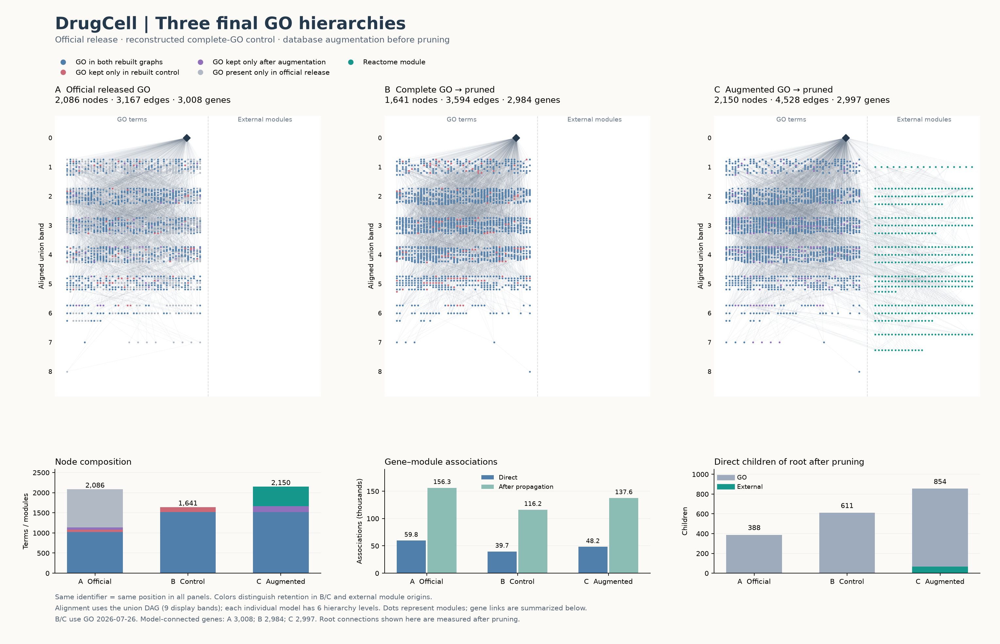

In [2]:
display(Image(filename=str(ARTIFACTS / "overview.png"), width=1600))


## Exact graph sizes and overlap

The counts below are calculated from the model input files. Node and edge overlap compares identifiers and exact parent–child pairs. Direct gene memberships refer to the exported graph, including membership recovery after node contraction.


In [3]:
rows = []
for stage in data["stages"]:
    s = stage["stats"]
    rows.append({"graph": stage["short_title"], "modules": s["terms"],
                 "hierarchy edges": s["hierarchy_edges"], "connected genes": s["annotated_genes"],
                 "direct gene links": s["direct_memberships"],
                 "propagated gene links": s["propagated_memberships"],
                 "hierarchy levels": s["hierarchy_levels"], "root children": stage["root_children"]})
display(pd.DataFrame(rows).set_index("graph"))

rows = []
for comparison, fields in data["comparisons"].items():
    for field, values in fields.items():
        rows.append({"comparison": comparison, "element": field,
                     "shared": values["shared"], "added": values["added"],
                     "removed": values["removed"], "Jaccard": round(values["jaccard"], 4)})
display(pd.DataFrame(rows).set_index(["comparison", "element"]))


,modules,hierarchy edges,connected genes,direct gene links,propagated gene links,hierarchy levels,root children
graph,,,,,,,
Official,2086,3167,3008,59753,156257,6,388
Rebuilt control,1641,3594,2984,39722,116215,6,611
Augmented,2150,4528,2997,48155,137596,6,854


shared  added  removed  Jaccard
comparison            element                                     
released_to_control   terms          1080    561     1006   0.4080
                      edges          1062   2532     2105   0.1863
                      memberships   16317  23405    43436   0.1962
control_to_augmented  terms          1515    635      126   0.6656
                      edges          2987   1541      607   0.5817
                      memberships   35405  12750     4317   0.6747
released_to_augmented terms          1077   1073     1009   0.3409
                      edges          1056   3472     2111   0.1591
                      memberships   16144  32011    43609   0.1759

## Local structure: DNA repair

This view includes the selected module and the union of its immediate parents and children across all three graphs. Filled nodes and arrows represent connections present in that graph; faint empty circles mark coordinates occupied in another graph. Colors match the overview. Change `TERM` in the setup cell and rerun the cell below to inspect another module.


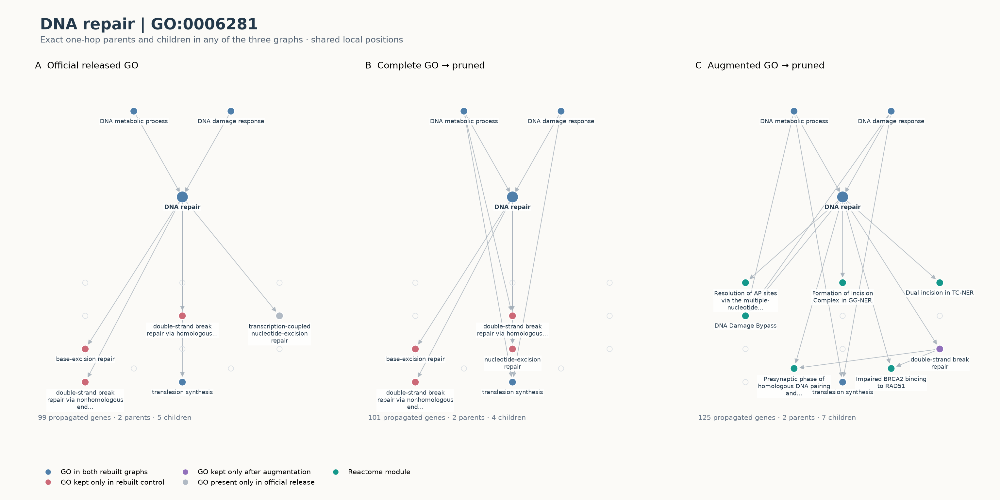

,present,direct genes,propagated genes
graph,,,
Official,True,46,99
Rebuilt control,True,73,101
Augmented,True,76,125


In [4]:
sys.path.insert(0, str(ROOT / "scripts"))
from visualize_drugcell_full_go import plot_neighborhood
NOTEBOOK_EXPORTS = ROOT / "outputs/notebooks/03_drugcell_three_graphs_006"
NOTEBOOK_EXPORTS.mkdir(parents=True, exist_ok=True)


def show_module(identifier):
    plot_neighborhood(data, NOTEBOOK_EXPORTS, identifier, name="selected_module")
    display(Image(filename=str(NOTEBOOK_EXPORTS / "selected_module.png"), width=1600))
    rows = []
    for stage in data["stages"]:
        node = node_maps[stage["id"]].get(identifier)
        rows.append({"graph": stage["short_title"], "present": node is not None,
                     "direct genes": len(node["direct"]) if node else 0,
                     "propagated genes": len(node["coverage"]) if node else 0})
    display(pd.DataFrame(rows).set_index("graph"))

show_module(TERM)


## Follow a measured gene

Change `GENE` in the setup cell to inspect its direct and ancestor-propagated memberships. `ALPP`, for example, has connections in A/C and zero connections in B. This table uses exact exported memberships for each graph.


In [5]:
def inspect_gene(gene):
    index = data["genes"].index(gene.upper())
    memberships, counts, terms = {}, [], set()
    for stage in data["stages"]:
        direct = {n["id"] for n in stage["nodes"] if index in n["direct"]}
        propagated = {n["id"] for n in stage["nodes"] if index in n["coverage"]}
        memberships[stage["id"]] = (direct, propagated)
        terms.update(direct)
        counts.append({"graph": stage["short_title"], "direct modules": len(direct),
                       "propagated modules": len(propagated), "connected input": bool(direct)})
    display(pd.DataFrame(counts).set_index("graph"))
    rows = []
    for term in sorted(terms):
        row = {"term": term, "label": all_nodes[term]["label"],
               "group": all_nodes[term]["comparison_group"]}
        for stage in data["stages"]:
            direct, propagated = memberships[stage["id"]]
            row[stage["short_title"]] = "direct" if term in direct else "inherited" if term in propagated else "absent"
        rows.append(row)
    return pd.DataFrame(rows)


gene_memberships = inspect_gene(GENE)
with pd.option_context("display.max_rows", 30, "display.max_colwidth", 55):
    display(gene_memberships)


,direct modules,propagated modules,connected input
graph,,,
Official,127,312,True
Rebuilt control,70,159,True
Augmented,90,212,True


,term,label,group,Official,Rebuilt control,Augmented
0,EXTERNAL:R-HSA-114452,Activation of BH3-only proteins,Reactome module,absent,absent,direct
1,EXTERNAL:R-HSA-1912408,Pre-NOTCH Transcription and Translation,Reactome module,absent,absent,direct
2,EXTERNAL:R-HSA-2559586,DNA Damage/Telomere Stress Induced Senescence,Reactome module,absent,absent,direct
3,EXTERNAL:R-HSA-445989,TAK1-dependent IKK and NF-kappa-B activation,Reactome module,absent,absent,direct
4,EXTERNAL:R-HSA-5628897,TP53 Regulates Metabolic Genes,Reactome module,absent,absent,direct
...,...,...,...,...,...,...
196,GO:2000279,negative regulation of DNA biosynthetic process,GO present only in official release,direct,absent,absent
197,GO:2000377,regulation of reactive oxygen species metabolic pro...,GO in both rebuilt graphs,inherited,direct,direct
198,GO:2000379,positive regulation of reactive oxygen species meta...,GO present only in official release,direct,absent,absent
199,GO:2000772,regulation of cellular senescence,GO kept only in rebuilt control,direct,direct,absent


## Interactive viewer

Search a gene, GO ID, module label or Reactome ID. Select neighborhoods, ancestors, descendants or gene connections; zoom and pan are synchronized. The color selector switches between graph identity and knowledge origin. Hover displays each node's actual depth within its own graph.

The viewer is self-contained and runs offline. A standalone copy is stored alongside the figures as `index.html`.


In [6]:
viewer = (ARTIFACTS / "index.html").read_text()
display(HTML('<iframe title="Three final DrugCell GO graphs" sandbox="allow-scripts allow-downloads" '
             'style="width:100%;height:1300px;border:1px solid #dce3e9;border-radius:10px" '
             'srcdoc="' + html.escape(viewer, quote=True) + '"></iframe>'))


/home/yxcheng/project/GO_enrichment/.venv/lib/python3.12/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## Figure and data exports

PNG, SVG and PDF versions are available for the overview and DNA-repair example. `nodes.tsv` and `edges.tsv` contain every plotted node and hierarchy edge; `manifest.json` pins the source hashes. Regenerate the artifacts into a new directory using `scripts/visualize_drugcell_full_go.py`.


In [7]:
for filename in ["overview.png", "overview.svg", "overview.pdf", "dna_repair.png", "dna_repair.svg",
                 "dna_repair.pdf", "index.html", "nodes.tsv", "edges.tsv", "summary.json", "manifest.json"]:
    path = ARTIFACTS / filename
    print(f"{path.relative_to(ROOT)} ({path.stat().st_size / 1024**2:.2f} MiB)")


outputs/analysis/drugcell_three_graphs_006_001/overview.png (1.95 MiB)
outputs/analysis/drugcell_three_graphs_006_001/overview.svg (2.42 MiB)
outputs/analysis/drugcell_three_graphs_006_001/overview.pdf (0.14 MiB)
outputs/analysis/drugcell_three_graphs_006_001/dna_repair.png (0.42 MiB)
outputs/analysis/drugcell_three_graphs_006_001/dna_repair.svg (0.06 MiB)
outputs/analysis/drugcell_three_graphs_006_001/dna_repair.pdf (0.03 MiB)
outputs/analysis/drugcell_three_graphs_006_001/index.html (5.49 MiB)
outputs/analysis/drugcell_three_graphs_006_001/nodes.tsv (0.57 MiB)
outputs/analysis/drugcell_three_graphs_006_001/edges.tsv (0.36 MiB)
outputs/analysis/drugcell_three_graphs_006_001/summary.json (0.00 MiB)
outputs/analysis/drugcell_three_graphs_006_001/manifest.json (0.00 MiB)
